# A012 · 기타 자산군–KOSPI200 상관 시각화: 코스닥 · 미국주식 · 금 · 원유 · 달러 · 국내 섹터

**Track A · Phase A2-②**. A01 과 같은 계약(일간 로그수익률, `dq_trim_canonical`, 0.9w min_periods, `rank_safe`)으로 KOSPI200(069500) 대비
채권이 아닌 자산들의 rolling 상관을 비교한다.

| 묶음 | ETF | 구조 메모 (universe.csv) |
|---|---|---|
| 국내 주식 | `229200` KOSDAQ150 | same_session |
| 미국 주식 | `219480` S&P500 선물(H) · `133690` NASDAQ100 | H=환헤지/선물, 133690 비헤지/현물 · overnight_lag |
| 원자재 | `132030` 골드선물(H) · `261220` WTI원유선물(H) | 선물·환헤지 · overnight_lag |
| FX | `261240` 미국달러선물 | same_session · DQ 2일(2019-03-14·15) |
| 국내 섹터·구조 (기본 패널 밖, 비교용) | 091230·091170·091180·305540·143860·117680·161510·192090 · 122630(2x)·114800(−1x) | 122630·114800 은 KOSPI200 과 같은 exposure group |

**연구 질문**
1. 자산군에 따라 KOSPI200 과의 관계가 '수준'과 '변동'에서 어떻게 다른가? 채권과 무엇이 다른가?
2. 해외 ETF 의 같은 날 상관은 거래시간 비동기로 왜곡되는가?
3. 환헤지(H) 여부는 상관을 어떻게 바꾸는가?
4. 항상 양(+)의 상관을 보이는 ETF 는 무엇이 다른가?
5. 달러선물 이상치와 원유 극단값은 결론을 얼마나 바꾸는가?

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "research_a_contract.yaml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.kfont import setup_korean_font
from src.r2h.research_a import contract as K, data as D, qa as Q
from src.r2h.research_a import rolling_correlation as RC, robustness as RB, visualization as V
from src.r2h.research_a import correlation_events as CE, price_events as PE, event_matching as EM

setup_korean_font()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

C = K.load_contract(ROOT)
VERSION = K.input_data_version(D.read_manifest(C))
REF = C.reference
SPEC = D.etf_manifest(C).set_index("ticker")
LAB = {t: f"{t} {SPEC.at[t, 'name']}" for t in SPEC.index}
FIG_DIR = ROOT / "reports" / "r2h" / "research_a" / "figures" / "A012"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    p = FIG_DIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight", dpi=110)
    return p

assert D.verify_raw_sha(C)["match"].all(), "raw sha mismatch"
r = D.returns(C, "dq_trim_canonical")      # 실제 데이터 · 일간 로그수익률(logdiff) · 261240 DQ 2일 NaN
rr = D.returns(C, "raw")                   # DQ 처리 없음 (민감도용)
close = D.load_close_panel(C)              # KRW, 20종 공통 거래일
print("ROOT:", ROOT, "| input_version:", VERSION[:16], "| sha:", K.git_sha(ROOT)[:10], "| r:", r.shape, r.index[0].date(), "~", r.index[-1].date())

ROOT: /home/sieg/projects-wsl/hongik_univ_26_2/SA/.worktrees/SA_ETF/codex-a | input_version: fd9713f7f985e950 | sha: 95b93ea846 | r: (1902, 20) 2019-01-03 ~ 2026-10-02


## 1. 자산군 지도 — 원 유니버스 필드와 A 분석 필드

`etf_pair_manifest` 는 쌍마다 기준 역할(primary 069500 / control 102110), 거래시간 동기(`session_sync`), 환헤지를 기록한다.
같은 기초지수 중복(`a_exposure_group`)은 사건 집계에서 1건으로 센다(A00 §2).

In [2]:
OTH = ["229200", "219480", "133690", "132030", "261220", "261240"]
SEC = ["091230", "091170", "091180", "305540", "143860", "117680", "161510", "192090"]
GEAR = ["122630", "114800"]
cols = ["name", "asset_scope", "benchmark", "currency_hedge", "replication", "leverage_inverse", "a_exposure_group", "a_session_sync", "a_analysis_role"]
display(SPEC.loc[OTH + SEC + GEAR, cols])

,name,asset_scope,benchmark,currency_hedge,replication,leverage_inverse,a_exposure_group,a_session_sync,a_analysis_role
ticker,,,,,,,,,
229200,KODEX 코스닥150,domestic_equity,KOSDAQ 150,n/a (KRW),physical,none,229200,same_session,comparison
219480,KODEX 미국S&P500선물(H),foreign_equity,S&P 500 선물 (환헤지),hedged (H),futures,none,219480,overnight_lag,comparison
133690,TIGER 미국나스닥100,foreign_equity,NASDAQ-100,unhedged,physical,none,133690,overnight_lag,comparison
132030,KODEX 골드선물(H),commodity,S&P GSCI Gold (선물; 추정),hedged (H),futures,none,132030,overnight_lag,comparison
261220,KODEX WTI원유선물(H),commodity,S&P GSCI Crude Oil (선물; 추정),hedged (H),futures,none,261220,overnight_lag,comparison
261240,KODEX 미국달러선물,fx,미국달러선물 (KRX USD/KRW 선물),n/a (USD 롱 노출이 목적),futures,none,261240,same_session,comparison
091230,TIGER 반도체,domestic_equity,KRX 반도체 (추정),n/a (KRW),physical,none,091230,same_session,not_in_base_panel
091170,KODEX 은행,domestic_equity,KRX 은행 (추정),n/a (KRW),physical,none,091170,same_session,not_in_base_panel
091180,KODEX 자동차,domestic_equity,KRX 자동차 (추정),n/a (KRW),physical,none,091180,same_session,not_in_base_panel


## 2. 정적 상관과 연도별 상관 — 수준의 차이

Pearson/Spearman 정의는 A01 §2. 연도별 값은 각 해 안의 정적 상관이다(창 = 그 해 전체).

,full_pearson,full_spearman,dev_2019_2024_pearson,val_2025_pearson,holdout_2026_pearson
ticker,,,,,
229200 KODEX 코스닥150,0.686,0.647,0.730,0.693,0.675
219480 KODEX 미국S&P500선물(H),0.544,0.610,0.677,0.649,0.599
133690 TIGER 미국나스닥100,0.448,0.422,0.490,0.579,0.593
132030 KODEX 골드선물(H),0.268,0.176,0.195,0.142,0.387
261220 KODEX WTI원유선물(H),0.060,0.150,0.310,0.152,-0.363
261240 KODEX 미국달러선물,-0.458,-0.519,-0.579,-0.384,-0.409
091230 TIGER 반도체,0.863,0.777,0.786,0.858,0.948
091170 KODEX 은행,0.535,0.533,0.667,0.586,0.421
091180 KODEX 자동차,0.663,0.619,0.702,0.609,0.670


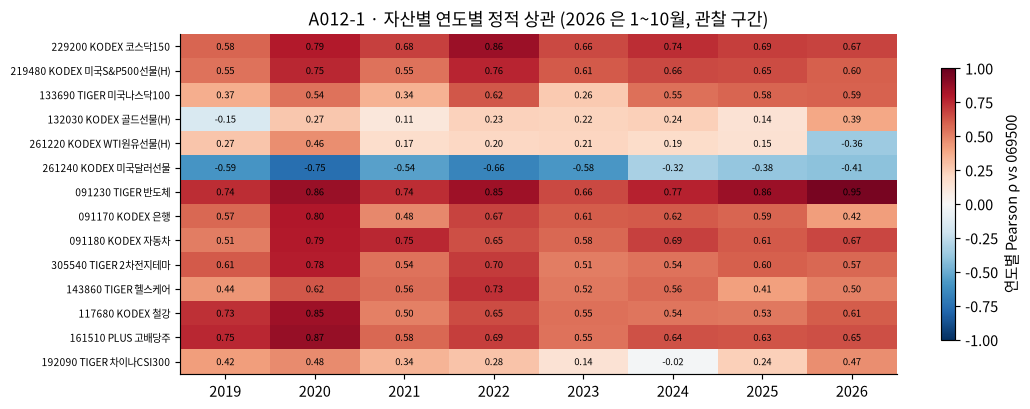

In [3]:
st = RB.static_corr_by_period(r, REF, OTH + SEC + GEAR).set_index("ticker")
yr = st[[c for c in st.columns if c.startswith("y")]]
display(st[["full_pearson", "full_spearman", "dev_2019_2024_pearson", "val_2025_pearson", "holdout_2026_pearson"]].rename(index=LAB).round(3))
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(yr.loc[OTH + SEC].values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_yticks(range(len(OTH + SEC))); ax.set_yticklabels([LAB[t] for t in OTH + SEC], fontsize=7)
ax.set_xticks(range(yr.shape[1])); ax.set_xticklabels(yr.columns.str[1:])
for i, t in enumerate(OTH + SEC):
    for j, c in enumerate(yr.columns):
        ax.text(j, i, f"{yr.at[t, c]:.2f}", ha="center", va="center", fontsize=6.5)
ax.grid(False); fig.colorbar(im, shrink=.8, label="연도별 Pearson ρ vs 069500")
ax.set_title("A012-1 · 자산별 연도별 정적 상관 (2026 은 1~10월, 관찰 구간)"); savefig(fig, "01_yearly_heatmap"); plt.show()
assert abs(st.at["261220", "y2026"] + 0.363) < 2e-3 and abs(st.at["261220", "dev_2019_2024_pearson"] - 0.310) < 2e-3
assert (yr.loc[["229200", "219480"]] > 0.5).all().all() and (yr.loc["261240"] < -0.3).all()

### 해석
- **본 것**: 229200(코스닥) 0.69, 219480(S&P H) 0.54, 133690(NASDAQ) 0.45 는 **매년 양(+)** — 229200·219480 은 매년 0.5 이상.
  261240(달러) 은 **매년 음(−)** (−0.75 ~ −0.32). 132030(금)은 2019 −0.15 를 빼면 양(+).
  **261220(원유)** 만 부호가 뒤집힌다: 2019-24 **+0.31** → 2026 **−0.36**.
- **채권과의 차이**: 148070 은 해마다 −0.40 ~ +0.37 을 오갔지만(A01 §2), 주식·달러는 *부호가 고정*되고 크기만 변한다.
  즉 "상관 전환"이라는 질문 자체가 성립하는 자산은 채권·금·원유이고, 주식·달러는 '강도 변화'의 문제다.
- **국내 섹터**: 091230(반도체) 0.86 이 가장 높고 192090(CSI300) 0.28 이 가장 낮다. 섹터는 KOSPI 의 일부라 높은 양(+) 상관은 구성상 당연하다.

> **재구성 질문** — 261220 의 전체표본 ρ=0.06 이 "원유와 주식은 무관하다"를 뜻하지 않는 이유를 연도별 값으로 설명하라.

## 3. 30 · 60 · 120 일 rolling 상관 — 자산군 비교

6개 자산을 같은 축 범위(−1~1)에 놓고 세 창을 겹친다. 회색 = 60일 근사 오차대 ±0.25 (독립 가정 근사, 정식 검정 아님).

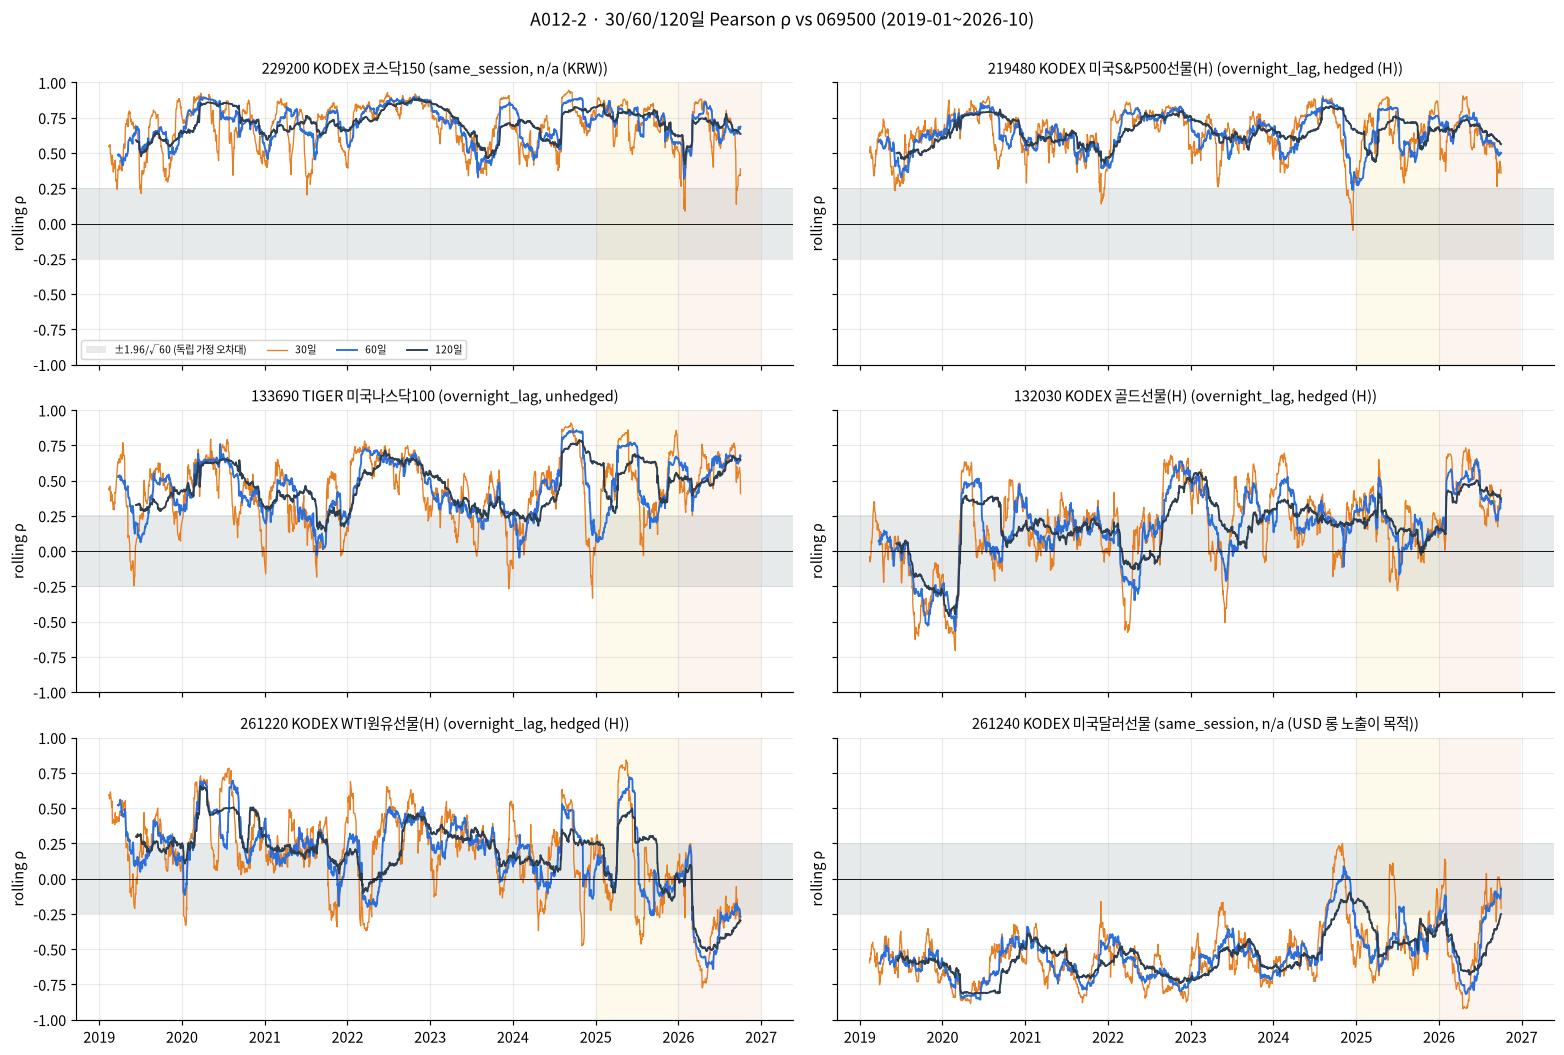

/tmp/ipykernel_72774/2540619911.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "n_regime_b0.1_k10", "mean_dev_2019_2024", "mean_val_2025", "mean_holdout_2026"]].round(3))


,ticker,window,method,mean,sd,min,min_at,max,share_pos,share_within_null_band,n_zero_cross,n_regime_b0.1_k10,mean_dev_2019_2024,mean_val_2025,mean_holdout_2026
0,229200,30,pearson,0.681,0.167,0.087,2026-01-30,0.945,0.986,0.042,0,0,0.681,0.724,0.626
1,229200,30,spearman,0.644,0.167,0.049,2021-07-07,0.923,0.986,0.055,0,0,0.655,0.628,0.583
2,229200,60,pearson,0.702,0.125,0.316,2026-01-26,0.898,0.972,0.000,0,0,0.701,0.740,0.667
3,229200,60,spearman,0.656,0.122,0.354,2023-08-07,0.910,0.972,0.000,0,0,0.667,0.642,0.591
4,229200,120,pearson,0.715,0.097,0.421,2026-01-30,0.883,0.944,0.000,0,0,0.713,0.755,0.677
5,229200,120,spearman,0.664,0.093,0.466,2023-09-13,0.888,0.944,0.000,0,0,0.674,0.658,0.597
6,229200,250,pearson,0.730,0.065,0.575,2019-11-29,0.854,0.882,0.000,0,0,0.729,0.766,0.691
7,229200,250,spearman,0.672,0.073,0.532,2026-07-03,0.854,0.882,0.000,0,0,0.686,0.668,0.582
8,219480,30,pearson,0.635,0.156,-0.048,2024-12-18,0.906,0.984,0.057,2,0,0.634,0.651,0.619
9,219480,30,spearman,0.599,0.172,-0.070,2025-07-31,0.908,0.982,0.094,6,0,0.608,0.530,0.619


In [4]:
rhos = {t: {w: RC.rolling_corr(r[t], r[REF], w, min_periods=int(np.ceil(.9 * w)))["rho"] for w in (30, 60, 120)} for t in OTH + SEC + GEAR}
fig, axs = plt.subplots(3, 2, figsize=(15, 10), sharex=True, sharey=True)
for a, t in zip(axs.ravel(), OTH):
    V.rho_panel(a, rhos[t], title=f"{LAB[t]} ({SPEC.at[t, 'a_session_sync']}, {SPEC.at[t, 'currency_hedge']})", band_window=60, legend=(t == OTH[0]))
    V.shade_periods(a)
fig.suptitle("A012-2 · 30/60/120일 Pearson ρ vs 069500 (2019-01~2026-10)", y=1.0); fig.tight_layout(); savefig(fig, "02_rolling_grid"); plt.show()
ws = RB.window_summary(r, REF, OTH, (30, 60, 120, 250), ("pearson", "spearman"))
display(ws[["ticker", "window", "method", "mean", "sd", "min", "min_at", "max", "share_pos", "share_within_null_band", "n_zero_cross",
            "n_regime_b0.1_k10", "mean_dev_2019_2024", "mean_val_2025", "mean_holdout_2026"]].round(3))
p = ws[ws.method == "pearson"].set_index(["ticker", "window"])
assert p.loc[("229200", 120), "n_zero_cross"] == 0 and p.loc[("219480", 60), "n_zero_cross"] == 0 and p.loc[("261240", 120), "n_zero_cross"] == 0
assert p.loc[("132030", 30), "n_zero_cross"] == 91 and p.loc[("261220", 30), "n_zero_cross"] == 59

### 해석 — 창 민감도
- **부호가 고정된 쌍**: 229200·219480 은 60·120일에서 0선 교차 **0번**(229200 은 30일도 0). 261240 은 120일 0번, 60일 2번, 30일 10번.
  133690 은 30일 28번 → 60일 4번 → 120일 0번 — **짧은 창에서만 0 근처를 오간다** (2024-12~2025 초 저점).
- **부호가 바뀌는 쌍**: 132030(금) 30일 91 · 60일 42 · 120일 12, 261220(원유) 59 · 43 · 13. 채권(148070 55·45·41)보다 긴 창에서 빨리 줄어든다 →
  금·원유의 교차는 짧은 국면 진동이 많고, 장기 국면 전환은 적다.
- **원유 2026**: 60일 ρ 평균 2019-24 0.24 → 2026 **−0.30**, 2026 의 82% 가 음(−). 기존 CL-31("WTI–주식 상관의 부호 반전")과 같은 현상을 pair 수준에서 재확인.
- **250일**: 모든 자산에서 교차가 가장 적다(기존 분석 창). 긴 창은 국면 '존재'를 보이지만 '시점'을 흐린다.

> **재구성 질문** — 133690 의 0선 교차가 30일에서 28번, 120일에서 0번인 것을 근거로 "나스닥–KOSPI 관계는 안정적"이라고 말할 수 있는가?

## 4. 항상 양(+)의 상관을 보이는 ETF — 무엇이 다른가

ρ 가 거의 항상 양(+)이면 0선 교차 기반 사건(C1·C3)은 **정의상 생기지 않는다**. 이런 쌍에서 관계 변화는 *크기*(C2 Fisher z)로만 볼 수 있다.
양(+)의 비율과 최저값, 공통 요인(시장 위험)의 크기를 본다.

In [5]:
pos = pd.DataFrame({t: {"share_rho60_pos": (rhos[t][60].dropna() > 0).mean(), "min_rho60": rhos[t][60].min(),
                         "min_at": rhos[t][60].idxmin().date(), "full_rho": r[t].corr(r[REF]),
                         "beta_vs_069500": r[t].cov(r[REF]) / r[REF].var()} for t in OTH + SEC + GEAR}).T
display(pos.sort_values("share_rho60_pos", ascending=False).rename(index=LAB))
always = sorted(pos.index[pos.share_rho60_pos == 1.0]); print('60일 ρ 항상 양(+):', always)
assert always == sorted(['229200', '219480', '091230', '091170', '091180', '305540', '143860', '117680', '161510', '122630'])
assert abs(float(pos.loc["122630", "beta_vs_069500"]) - 1.986) < 5e-3 and abs(float(pos.loc["114800", "beta_vs_069500"]) + 1.016) < 5e-3

,share_rho60_pos,min_rho60,min_at,full_rho,beta_vs_069500
229200 KODEX 코스닥150,1.0,0.315662,2026-01-26,0.685919,0.806452
219480 KODEX 미국S&P500선물(H),1.0,0.23913,2024-12-18,0.544113,0.360831
091230 TIGER 반도체,1.0,0.480958,2024-04-15,0.862619,1.180782
091170 KODEX 은행,1.0,0.101377,2026-09-29,0.534878,0.514513
091180 KODEX 자동차,1.0,0.136748,2023-07-13,0.662693,0.727803
305540 TIGER 2차전지테마,1.0,0.057137,2023-08-01,0.571739,0.820548
143860 TIGER 헬스케어,1.0,0.072449,2026-01-26,0.508368,0.549553
117680 KODEX 철강,1.0,0.07963,2025-11-03,0.593985,0.683051
161510 PLUS 고배당주,1.0,0.300827,2021-05-28,0.654668,0.486653
122630 KODEX 레버리지,1.0,0.99436,2020-03-17,0.997843,1.986003


60일 ρ 항상 양(+): ['091170', '091180', '091230', '117680', '122630', '143860', '161510', '219480', '229200', '305540']


### 해석
- **본 것**: 60일 ρ 가 **항상 양(+)** 인 것은 229200 · 219480 · 091230 · 091170 · 091180 · 305540 · 143860 · 117680 · 161510 — 모두 주식형이다(60일 최저 0.06~0.48).
  122630(2x)·114800(−1x)은 β ≈ 1.99 / −1.02 로 **상관 ±0.998** — 상품 구조가 만든 상관이지 시장 관계가 아니다(같은 exposure group).
- **왜 항상 양(+)인가**: 같은 '주식 위험 요인'을 공유하기 때문이다. 미국 주식도 KRX 거래 시간 안에 선물·환율로 같은 날 위험을 반영한다(§6).
- **연구상 의미**: 이런 쌍에는 "상관 전환 → 급등" 가설을 적용할 대상이 없다. A02 의 사례 표에서 229200·219480·133690 의 공동 발생 유형이
  '존재하지 않음'으로 나오는 이유다(억지로 만들지 않는다).

> **재구성 질문** — 122630 과 069500 의 상관 0.998 을 두 개의 독립 시장 신호로 세면 사건 비교에서 무엇이 왜곡되는가?

## 5. 환헤지(H)와 기초지수 — 219480 vs 133690

- 219480 : S&P500 **선물 · 환헤지** → 원/달러 노출 제거
- 133690 : NASDAQ100 **현물 · 비헤지** → 수익률 ≈ 지수 + 원/달러 변화
원/달러 상승(원화 약세)은 보통 KOSPI 하락과 같이 온다(261240 ρ=−0.46). 그러면 비헤지 ETF 는 달러 강세로 원화 환산 수익이 늘어 **KOSPI 하락을 일부 상쇄** → KOSPI 와의 상관이 낮아질 것으로 예상할 수 있다.

,rho_vs_069500,rho_vs_261240_usd,partial_rho_vs_069500_given_usd
219480 KODEX 미국S&P500선물(H),0.544,-0.469,0.420
133690 TIGER 미국나스닥100,0.448,-0.101,0.454


corr(133690 − 219480 수익률 차, 261240) = 0.575 · corr(219480, 133690) = 0.838


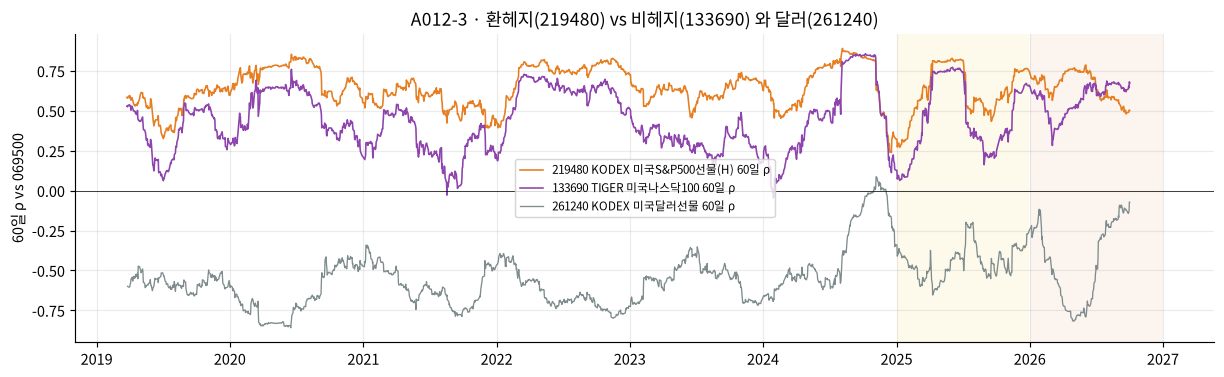

In [6]:
diff = r["133690"] - r["219480"]
pc = {}
for t in ("219480", "133690"):
    X = r[[t, REF, "261240"]].dropna(); Pm = np.linalg.inv(X.corr().values)
    pc[t] = -Pm[0, 1] / np.sqrt(Pm[0, 0] * Pm[1, 1])
hed = pd.DataFrame({"rho_vs_069500": [r["219480"].corr(r[REF]), r["133690"].corr(r[REF])],
                    "rho_vs_261240_usd": [r["219480"].corr(r["261240"]), r["133690"].corr(r["261240"])],
                    "partial_rho_vs_069500_given_usd": [pc["219480"], pc["133690"]]}, index=[LAB["219480"], LAB["133690"]])
display(hed.round(3))
print("corr(133690 − 219480 수익률 차, 261240) =", round(diff.corr(r["261240"]), 3), "· corr(219480, 133690) =", round(r["219480"].corr(r["133690"]), 3))
fig, ax = plt.subplots(figsize=(14, 3.8))
for t, col in (("219480", "#e67e22"), ("133690", "#8e44ad")):
    ax.plot(rhos[t][60].index, rhos[t][60], color=col, lw=1.1, label=f"{LAB[t]} 60일 ρ")
ax.plot(rhos["261240"][60].index, rhos["261240"][60], color="#7f8c8d", lw=.9, label=f"{LAB['261240']} 60일 ρ")
ax.axhline(0, c="k", lw=.5); ax.legend(fontsize=8); ax.set_ylabel("60일 ρ vs 069500"); V.shade_periods(ax)
ax.set_title("A012-3 · 환헤지(219480) vs 비헤지(133690) 와 달러(261240)"); savefig(fig, "03_hedge"); plt.show()
assert abs(hed.iloc[0, 1] + 0.469) < 3e-3 and abs(hed.iloc[1, 1] + 0.101) < 3e-3 and abs(diff.corr(r["261240"]) - 0.575) < 3e-3

### 해석
- **본 것**: 219480(H)–달러 ρ = **−0.47**, 133690(비헤지)–달러 ρ = **−0.10**. 두 ETF 수익률 차이(133690−219480)는 달러와 **+0.58** — 차이의 상당 부분이 환노출이다.
  KOSPI 와의 상관은 219480 0.54 > 133690 0.45. 달러를 통제한 부분상관은 0.42 vs 0.45 로 순서가 뒤집힌다.
- **의미**: 비헤지 ETF 의 낮은 KOSPI 상관은 '미국 기술주가 덜 동조해서'만이 아니라 **환율 완충** 효과가 섞인 결과다.
  기초지수(S&P vs NASDAQ) 차이와 환헤지 차이가 한 쌍 비교 안에 섞여 있어 둘을 분리하려면 같은 지수의 H/비헤지 쌍이 필요하다 — 현재 유니버스에 없다.

> **재구성 질문** — 같은 미국 주식 ETF 인데 헤지 여부만으로 KOSPI 와의 상관이 달라지는 경로를 달러–KOSPI 상관으로 설명하라.

## 6. 거래시간 비동기 — 해외 ETF 의 '같은 날'은 같은 정보인가

KRX 상장 해외 ETF 의 종가는 (전일 미국장 + 당일 KRX 시간의 선물·환율)을 반영한다. 비동기가 크면 **lag ±1 상관**이 크게 나오고,
**2일·5일 합산 수익률 상관**이 1일 상관보다 커진다 (하루 어긋난 정보가 같은 블록에 들어가므로). Dimson(1979) 합산 진단도 함께 본다.

$\rho(L)=\mathrm{corr}(r^{\text{asset}}_{t+L}, r^{\text{KOSPI}}_t)$ — L=−1 : 자산의 어제 vs KOSPI 오늘.

In [7]:
ll = RC.lead_lag_corr(r, REF, OTH, lags=range(-2, 3))
display(ll.pivot(index="ticker", columns="lag", values="rho").rename(index=LAB).round(3))
agg = RC.aggregated_corr(r, REF, OTH, 2).merge(RC.aggregated_corr(r, REF, OTH, 5)[["ticker", "rho_5d"]], on="ticker")
agg["session_sync"] = agg.ticker.map(C.session_sync_of)
display(agg.set_index("ticker").rename(index=LAB).round(3))
per = RC.period_of(r.index)
llp = pd.concat([RC.lead_lag_corr(r, REF, OTH, lags=(-1, 0, 1), period_mask=per == k).assign(period=k) for k in RC.PERIODS])
display(llp.pivot_table(index="ticker", columns=["period", "lag"], values="rho").round(3))
pv = ll.pivot(index="ticker", columns="lag", values="rho")
assert (pv[0].abs() > pv[[-1, 1]].abs().max(axis=1)).all() and pv[[-1, 1]].abs().max().max() < 0.11
assert abs(llp[(llp.period == 'holdout_2026') & (llp.ticker == '261240') & (llp.lag == 1)].rho.iloc[0] - 0.271) < 3e-3
assert (agg.loc[agg.session_sync == "overnight_lag", "rho_2d"] < agg.loc[agg.session_sync == "overnight_lag", "rho_1d"] + 0.05).all()

lag,-2,-1,0,1,2
ticker,,,,,
132030 KODEX 골드선물(H),0.014,-0.035,0.268,-0.017,-0.023
133690 TIGER 미국나스닥100,-0.015,-0.032,0.448,-0.060,0.027
219480 KODEX 미국S&P500선물(H),0.016,-0.042,0.544,-0.067,0.063
229200 KODEX 코스닥150,-0.032,-0.108,0.686,-0.063,0.014
261220 KODEX WTI원유선물(H),0.048,0.011,0.060,-0.026,0.093
261240 KODEX 미국달러선물,-0.026,0.031,-0.458,0.103,-0.011


,rho_2d,rho_1d,n_blocks,rho_5d,session_sync
ticker,,,,,
229200 KODEX 코스닥150,0.650,0.686,951,0.574,same_session
219480 KODEX 미국S&P500선물(H),0.500,0.544,951,0.558,overnight_lag
133690 TIGER 미국나스닥100,0.401,0.448,951,0.413,overnight_lag
132030 KODEX 골드선물(H),0.262,0.268,951,0.234,overnight_lag
261220 KODEX WTI원유선물(H),0.042,0.060,951,0.100,overnight_lag
261240 KODEX 미국달러선물,-0.393,-0.458,951,-0.383,same_session


period dev_2019_2024               holdout_2026               val_2025              
lag               -1      0      1           -1      0      1       -1      0      1
ticker                                                                              
132030         0.009  0.195  0.032       -0.106  0.387 -0.074    0.057  0.142 -0.009
133690         0.022  0.490 -0.108       -0.158  0.593  0.038   -0.097  0.579 -0.079
219480        -0.014  0.677 -0.065       -0.121  0.599 -0.099   -0.125  0.649 -0.130
229200        -0.029  0.730 -0.075       -0.198  0.675 -0.066   -0.149  0.693 -0.004
261220        -0.056  0.310 -0.041        0.107 -0.363 -0.012    0.064  0.152 -0.023
261240         0.068 -0.579  0.030       -0.034 -0.409  0.271    0.060 -0.384  0.127

### 해석
- **본 것**: 모든 자산에서 lag 0 상관이 lag ±1, ±2 보다 크다 (전체표본 |ρ(±1)| ≤ 0.11, 최대 261240 lag+1 0.103). overnight_lag 자산(219480·133690·132030·261220)의 2일 합산 상관은 1일보다
  **오히려 낮거나 비슷**하다(219480 0.54 → 0.50, 133690 0.45 → 0.40).
- **의미**: KRX 거래시간 안에서 해외 ETF 가 선물·환율로 가격을 갱신하므로, 같은 날 비교가 정보 시점을 대체로 맞춘다. 비동기로 상관이 과소추정된다는 증거는 약하다.
  → A02 사건 비교는 **동일일 정렬**을 기본으로 하고, ±L 거래일 매칭 창이 남은 비동기를 흡수한다.
- **2026 예외**: 2026 구간에서는 261240 lag+1 이 **0.27**, 229200 lag−1 이 −0.20 으로 커진다 — 고변동 국면에서 달러선물이 KOSPI 를 하루 늦게 반영하는 성분이 생긴다.
  표본 184일이라 불확실하며(근사 오차대 ±0.14), 2026 은 이미 탐색된 관찰 구간이다.
- **한계**: 일간 종가만으로는 장중 시점 차이를 볼 수 없다. 미국 휴장일·한국 휴장일 차이(데이터 없는 날)는 다루지 않았다.

> **재구성 질문** — 2일 합산 상관이 1일 상관보다 낮게 나온 것은 비동기 가설에 대해 무엇을 말해 주는가?

## 7. 달러선물 이상치 — 2019-03-14·15 가 rolling ρ 를 언제까지 바꾸는가

A1: 261240 의 2019-03-14 Close 11,820 (전후 약 9,700) → r=+0.199, 다음 날 −0.195 (`price_anomaly_unverified`, 오류로 확정하지 않음).
raw 와 `dq_trim_canonical`(그 2일만 NaN)의 rolling ρ 를 비교한다.

전체표본 ρ(069500, 261240): raw = -0.3084 · dq_trim = -0.4577


,ticker,window,max_abs_diff,max_abs_diff_at,n_days_diff_gt_tol,first_affected,last_affected,n_sign_disagree,n_nan_a,n_nan_b,n_zero_cross_a,n_zero_cross_b
0,261240,30,0.590,2019-03-14,31,2019-03-14,2019-04-25,1,26,26,12,10
1,261240,60,0.471,2019-06-03,52,2019-03-27,2019-06-11,0,53,55,2,2
2,261240,120,0.440,2019-08-05,58,2019-06-14,2019-09-04,0,107,109,0,0


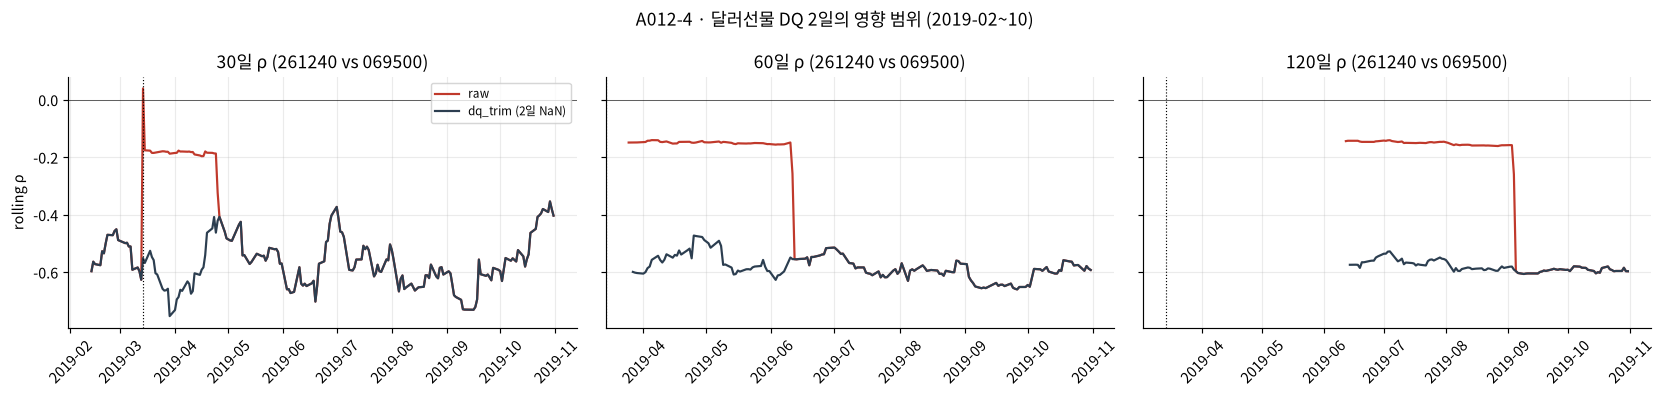

In [8]:
print("전체표본 ρ(069500, 261240): raw =", round(rr["261240"].corr(rr[REF]), 4), "· dq_trim =", round(r["261240"].corr(r[REF]), 4))
dq = RB.rolling_variant_diff(rr, r, REF, "261240"); display(dq.drop(columns=["method"]).round({"max_abs_diff": 3}))
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, w in zip(axs, (30, 60, 120)):
    ra = RC.rolling_corr(rr["261240"], rr[REF], w, min_periods=int(np.ceil(.9 * w)))["rho"].loc["2019-02":"2019-10"]
    rb = RC.rolling_corr(r["261240"], r[REF], w, min_periods=int(np.ceil(.9 * w)))["rho"].loc["2019-02":"2019-10"]
    a.plot(ra.index, ra, color="#c0392b", label="raw"); a.plot(rb.index, rb, color="#2c3e50", label="dq_trim (2일 NaN)")
    a.axvline(pd.Timestamp("2019-03-14"), color="k", lw=.8, ls=":"); a.set_title(f"{w}일 ρ (261240 vs 069500)"); a.axhline(0, c="k", lw=.4)
    a.tick_params(axis="x", rotation=45)
axs[0].legend(fontsize=8); axs[0].set_ylabel("rolling ρ")
fig.suptitle("A012-4 · 달러선물 DQ 2일의 영향 범위 (2019-02~10)"); fig.tight_layout(); savefig(fig, "04_usd_dq"); plt.show()
d = dq.set_index("window")
assert str(d.loc[30, "last_affected"].date()) == "2019-04-25" and str(d.loc[60, "last_affected"].date()) == "2019-06-11"
assert str(d.loc[120, "last_affected"].date()) == "2019-09-04" and d.loc[30, "max_abs_diff"] > 0.55

### 해석
- **재현**: 전체표본 ρ raw **−0.308** → dq_trim **−0.458** (A1 과 동일).
- **rolling 영향 범위** (|Δρ|>0.01 인 날): 30일 창 2019-03-14 ~ **04-25** (31일, 최대 0.59), 60일 03-27 ~ **06-11** (최대 0.47), 120일 06-14 ~ **09-04** (최대 0.44).
  이상치가 창 안에 있는 동안만 왜곡되고, 창 길이만큼 지나면 사라진다. 긴 창일수록 왜곡이 작지만 **오래** 간다.
- **사건에 주는 영향**: raw 의 30일 0선 교차 12번 중 2번이 2019 년(이상치 구간)에 생기고, trim 에서는 2019 교차 0번(A3 `dq_event_sensitivity.csv`).
  → 이 구간의 상관 사건은 '데이터 품질로 해석 불가' 유형이다.

> **재구성 질문** — 이틀짜리 이상치가 120일 창에서 왜 3개월 넘게 영향을 남기는가? 반대로 30일 창의 최대 왜곡이 더 큰 이유는?

## 8. 원유선물의 극단값 — 15% 초과 변동 8일

261220 은 flag 는 없지만 |단순수익률|>15% 인 날이 8일이다 (2020-03-09 −30%, 2020-04-22 −30%, 2026-03-09 +29% 등). 이 날들은 실제 극단값일 가능성이 높아 그대로 두지만,
창 하나를 지배할 수 있으므로 '가린 변형'을 민감도로 본다.

In [9]:
lm = Q.large_moves(C, ["261220"]); display(lm.round({"simple_ret": 4, "logret": 4}))
r_m = RB.mask_days(r, {"261220": list(lm.date)})
d2 = RB.rolling_variant_diff(r, r_m, REF, "261220"); display(d2.drop(columns=["method"]).round({"max_abs_diff": 3}))
print("전체표본 ρ(069500, 261220): 원래 =", round(r["261220"].corr(r[REF]), 3), "· 8일 가림 =", round(r_m["261220"].corr(r_m[REF]), 3))
per = RC.period_of(r.index)
print("60일 ρ 2026 평균: 원래", round(rhos["261220"][60][per == "holdout_2026"].mean(), 3), "· 8일 가림",
      round(RC.rolling_corr(r_m["261220"], r_m[REF], 60, min_periods=54)["rho"][per == "holdout_2026"].mean(), 3))
assert len(lm) == 8
assert abs(RC.rolling_corr(r_m["261220"], r_m[REF], 60, min_periods=54)["rho"][per == "holdout_2026"].mean() + 0.276) < 3e-3

,date,ticker,simple_ret,logret,has_dq_flag
0,2020-03-09,261220,-0.2997,-0.3563,False
1,2020-03-20,261220,0.1604,0.1487,False
2,2020-03-23,261220,-0.1593,-0.1736,False
3,2020-04-22,261220,-0.2997,-0.3563,False
4,2020-05-06,261220,0.2029,0.1848,False
5,2022-03-07,261220,0.1595,0.1479,False
6,2026-03-09,261220,0.2931,0.2571,False
7,2026-04-08,261220,-0.1768,-0.1946,False


,ticker,window,max_abs_diff,max_abs_diff_at,n_days_diff_gt_tol,first_affected,last_affected,n_sign_disagree,n_nan_a,n_nan_b,n_zero_cross_a,n_zero_cross_b
0,261220,30,0.251,2022-04-14,129,2020-03-09,2026-05-21,5,26,27,59,61
1,261220,60,0.162,2022-05-31,224,2020-03-09,2026-07-06,9,53,53,43,41
2,261220,120,0.139,2020-03-11,366,2020-03-09,2026-10-02,32,107,107,13,15


전체표본 ρ(069500, 261220): 원래 = 0.06 · 8일 가림 = 0.068
60일 ρ 2026 평균: 원래 -0.301 · 8일 가림 -0.276


### 해석
- 8일을 가리면 30일 ρ 가 최대 0.25, 120일 0.14 바뀐다. 0선 교차 수는 30일 59 → 61, 120일 13 → 15 — 결론(부호가 바뀌는 쌍)은 유지된다.
- 2026 의 음(−) 상관은 2026-03-09(+29%)·04-08(−18%)을 가려도 60일 평균 −0.30 → **−0.28** 로 남는다. 전체표본 ρ 도 0.060 → 0.068 — 소수 극단일의 산물이 아니라 그 해 전반의 성질이다.

> **재구성 질문** — 극단값을 '오류'로 지우는 것과 '가린 변형'으로 민감도를 보는 것은 연구 결론에 어떻게 다른 책임을 지는가?

## 9. 국내 섹터 · 구조 ETF — 기본 패널 밖 비교

기본 패널에 넣지 않은 국내 섹터와 중국 ETF 를 같은 창으로 요약한다. 섹터는 KOSPI 구성 일부라 높은 상관이 구조적이다.

/tmp/ipykernel_72774/2611800201.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(wsec[["ticker", "window", "mean", "min", "min_at", "share_pos", "n_zero_cross", "n_regime_b0.1_k10", "mean_holdout_2026"]].round(3))


,ticker,window,mean,min,min_at,share_pos,n_zero_cross,n_regime_b0.1_k10,mean_holdout_2026
0,091230,30,0.778,0.353,2024-02-29,0.986,0,0,0.926
1,091230,60,0.784,0.481,2024-04-15,0.972,0,0,0.933
2,091230,120,0.790,0.557,2023-09-05,0.944,0,0,0.924
3,091170,30,0.597,-0.332,2026-10-02,0.975,5,1,0.427
4,091170,60,0.612,0.101,2026-09-29,0.972,0,0,0.495
5,091170,120,0.620,0.240,2026-10-01,0.944,0,0,0.553
6,091180,30,0.628,-0.027,2023-06-21,0.985,2,0,0.640
7,091180,60,0.645,0.137,2023-07-13,0.972,0,0,0.672
8,091180,120,0.661,0.361,2023-09-14,0.944,0,0,0.673
9,305540,30,0.567,-0.019,2023-08-01,0.986,2,0,0.551


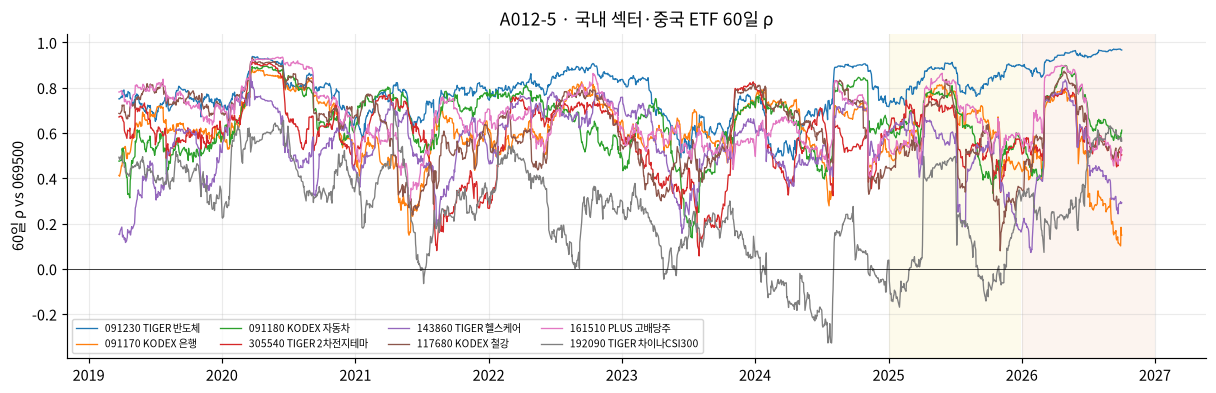

In [10]:
wsec = RB.window_summary(r, REF, SEC, (30, 60, 120), ("pearson",))
display(wsec[["ticker", "window", "mean", "min", "min_at", "share_pos", "n_zero_cross", "n_regime_b0.1_k10", "mean_holdout_2026"]].round(3))
fig, ax = plt.subplots(figsize=(14, 4))
for t in SEC:
    ax.plot(rhos[t][60].index, rhos[t][60], lw=.9, label=LAB[t])
ax.axhline(0, c="k", lw=.5); ax.legend(fontsize=7, ncol=4); ax.set_ylabel("60일 ρ vs 069500"); V.shade_periods(ax)
ax.set_title("A012-5 · 국내 섹터·중국 ETF 60일 ρ"); savefig(fig, "05_sectors"); plt.show()
ps = wsec.set_index(["ticker", "window"])
assert ps.loc[("192090", 30), "n_zero_cross"] == 56 and ps.loc[("091230", 60), "n_zero_cross"] == 0

### 해석
- 국내 섹터 7종은 60·120일 창에서 0선 교차가 **0번** (30일에서도 0~18번). 091230(반도체) 60일 평균 0.78, 2026 0.93 — KOSPI 의 대형주 집중을 반영.
- 192090(CSI300, partial_overlap)은 30일 교차 56번, C3 8번으로 주식 중 유일하게 부호가 오간다. 해외(중국)·부분 동기 거래의 성질.
- 이 결과는 "국내 주식형 ETF 는 KOSPI 와 상관 전환을 겪지 않는다"는 기존 SHOCK_MAP 의 공통충격 구조와 일관된다.

> **재구성 질문** — 섹터 ETF 의 높은 상관이 "섹터가 KOSPI 를 따라간다"는 인과를 뜻하지 않는 이유는?

## 10. A012 결론 — 자산군 비교표

| 자산 | 전체 ρ | 60일 교차 | 60일 C3 | 2026 60일 평균 | 성질 |
|---|---|---|---|---|---|
| 229200 코스닥 | 0.69 | 0 | 0 | 0.67 | 항상 양(+), 강도만 변화 |
| 219480 S&P(H) | 0.54 | 0 | 0 | 0.66 | 항상 양(+), 비동기 왜곡 약함 |
| 133690 NASDAQ | 0.45 | 4 | 0 | 0.57 | 짧은 창에서만 0 근처, 환노출이 상관을 낮춤 |
| 132030 금(H) | 0.27 | 42 | 6 | 0.42 | 부호 진동 많음, 장기 전환 적음 |
| 261220 원유(H) | 0.06 | 43 | 5 | −0.30 | 2026 부호 반전 (극단일 가려도 유지) |
| 261240 달러 | −0.46 | 2 | 0 | −0.44 | 항상 음(−), DQ 2일이 2019 창 지배 |
| (A01) 148070 국고채10년 | 0.13 | 45 | 13 | 0.30 | 해마다 부호 변화 |
| (A01) 153130 단기채 | 0.05 | 71 | 11 | 0.22 | 0 근처 잡음 우세 |

**채권과의 차이**: 상관 '전환'이 실제로 반복되는 것은 채권·금·원유다. 주식·달러는 부호가 고정돼 C1·C3 사건이 거의 없다.
→ A02 의 사건 비교는 자산군마다 **비교 가능한 사건의 수 자체가 다르다**는 점을 전제로 해석해야 한다.

In [11]:
w60 = ws[(ws.method == "pearson") & (ws.window == 60)].set_index("ticker")
assert w60.loc["132030", "n_regime_b0.1_k10"] == 6 and w60.loc["261220", "n_regime_b0.1_k10"] == 5 and w60.loc["133690", "n_zero_cross"] == 4
assert abs(w60.loc["261220", "mean_holdout_2026"] + 0.301) < 3e-3
print("A012 결론 표 수치 검증 통과")

A012 결론 표 수치 검증 통과
